# Reto 5 - Lagun Aro: Análisis descriptivo de los datos

En este notebook se hace un análisis descriptivo de los préstamos antes de construir los modelos de **impago** y **prima**.

Pasos:
1. Cargar los datos y revisar su estructura
2. Limpieza básica
3. Análisis de cada variable por separado
4. Análisis de la variable Impago
5. Relación entre las variables y el Impago
6. Análisis de la variable Prima
7. Correlaciones
8. Conclusiones

## 1. Carga de los datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
df = pd.read_csv("Preprocesado.csv")
df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Estudios,Tipo_Jornada_Laboral,Estado_Civil,Posesion_Hipoteca,Personas_Cargo,Proposito,Fiador,Impago,Prima
0,JKLXIQ,51,"56,857.000",102886,718,338.000,3,6.180,24.000,0.550,Grado Universitario,Desempleado,Casado,1.000,0.000,Negocios,0.000,0,580.000
1,4UO7DJ,46,"45,840.000",30473,689,291.000,1,14.280,36.000,0.340,Escolar,Desempleado,Casado,0.000,0.000,Negocios,0.000,0,431.250
2,MO3OJW,36,"48,156.000",188824,675,161.000,2,13.350,36.000,0.550,Grado Universitario,Jornada completa,Soltero,0.000,1.000,Negocios,0.000,0,760.000
3,I14TTP,42,"41,472.000",40000,582,312.000,1,11.830,12.000,0.440,Escolar,Jornada completa,Divorciado,1.000,1.000,Negocios,1.000,0,385.660
4,8FUIBH,60,"70,202.000",40743,652,489.000,2,9.270,48.000,0.250,Grado Universitario,Tiempo parcial,Casado,1.000,0.000,Negocios,1.000,0,535.140


Se viusaliza el tamaño de la base de datos y la infromacion de cada variable

In [3]:
print("Número de filas:", df.shape[0])
print("Número de columnas:", df.shape[1])

Número de filas: 76513
Número de columnas: 19


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 76513 entries, 0 to 76512
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    76513 non-null  str    
 1   Edad                  76513 non-null  int64  
 2   Ingresos              76513 non-null  float64
 3   Monto_Inicial         76513 non-null  int64  
 4   Scoring_Crediticio    76513 non-null  int64  
 5   Meses_Empleo          76513 non-null  float64
 6   Num_Creditos          76513 non-null  int64  
 7   Ratio_Interes         76513 non-null  float64
 8   Duracion              76513 non-null  float64
 9   Ratio_Deuda_Ingresos  76513 non-null  float64
 10  Estudios              76513 non-null  str    
 11  Tipo_Jornada_Laboral  76513 non-null  str    
 12  Estado_Civil          76513 non-null  str    
 13  Posesion_Hipoteca     76513 non-null  float64
 14  Personas_Cargo        76513 non-null  float64
 15  Proposito             76513 no

Hay 76.513 préstamos y 19 variables en la base de datos con variables numéricas (edad, ingresos, monto...) y categóricas (estudios, estado civil...). Las variables *Posesion_Hipoteca*, *Personas_Cargo* y *Fiador* están codificadas como 0/1.

## 2. Limpieza básica


### 2.1 Filas duplicadas

In [6]:
print("Filas duplicadas:", df.duplicated().sum())
print("IDs repetidos:", df["ID"].duplicated().sum())

Filas duplicadas: 3
IDs repetidos: 3


In [7]:
df = df.drop_duplicates()
print("Filas después de eliminar duplicados:", df.shape[0])

Filas después de eliminar duplicados: 76510


Hay 3 préstamos repetidos exactamente iguales (mismo ID y mismos datos) por lo que se desechan para no contarlos dos veces.

In [9]:
df = df.drop(columns=["Proposito"])

Todos los préstamos tienen el mismo propósito (*Negocios*). Una variable que siempre vale lo mismo no sirve para explicar nada, así que se excluyen.

### 2.4 Comprobaciones de lógica

In [10]:
# ¿Hay valores imposibles?
print("Edades menores de 18:", (df["Edad"] < 18).sum())
print("Ingresos negativos o cero:", (df["Ingresos"] <= 0).sum())
print("Primas negativas o cero:", (df["Prima"] <= 0).sum())

# Una persona no puede haber trabajado más meses de los que ha vivido desde los 16 años
meses_maximos = (df["Edad"] - 16) * 12
incoherentes = df[df["Meses_Empleo"] > meses_maximos]
print("Personas con más meses trabajados de lo posible:", len(incoherentes))
print("Porcentaje:", round(len(incoherentes) / len(df) * 100, 2), "%")

Edades menores de 18: 0
Ingresos negativos o cero: 0
Primas negativas o cero: 0
Personas con más meses trabajados de lo posible: 8535
Porcentaje: 11.16 %


In [11]:
incoherentes[["Edad", "Meses_Empleo"]].head()

,Edad,Meses_Empleo
27,41,334.000
37,50,418.000
39,42,314.000
46,57,498.000
47,43,368.000


No hay valores imposibles en edades, ingresos o primas. Pero **8.535 personas (11,2 %) tienen más meses trabajados de los que es posible para su edad**. Por ejemplo, alguien de 20 años no puede llevar 10 años trabajando. Son datos sospechosos que habría que comentar con el cliente.

In [12]:
# Valores que se repiten demasiado
print("Monto_Inicial - valores más repetidos:")
print(df["Monto_Inicial"].value_counts().head(3))
print()
print("Ratio_Deuda_Ingresos - valores más repetidos:")
print(df["Ratio_Deuda_Ingresos"].value_counts().head(3))

Monto_Inicial - valores más repetidos:
Monto_Inicial
40000    17154
5000      1401
3000      1261
Name: count, dtype: int64

Ratio_Deuda_Ingresos - valores más repetidos:
Ratio_Deuda_Ingresos
0.55    21705
0.10    13683
0.11     1723
Name: count, dtype: int64


En este caso ocurren dos cosas raras:

- **17.154 préstamos (22 %) tienen exactamente 40.000 €**. Es poco probable que tanta gente pida justo la misma cantidad; parece que los valores que faltaban se rellenaron con 40.000.
- En *Ratio_Deuda_Ingresos*, casi la mitad de los valores son 0,55 o 0,10, que son justo el máximo y el mínimo. Es probable que la variable se ha recortado en esos límites.

## 3. Análisis de cada variable
### 3.1 Variables numéricas

In [13]:
numericas = ["Edad", "Ingresos", "Monto_Inicial", "Scoring_Crediticio", "Meses_Empleo",
             "Num_Creditos", "Ratio_Interes", "Duracion", "Ratio_Deuda_Ingresos", "Prima"]
df[numericas].describe().round(2)

,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Prima
count,"76,510.000","76,510.000","76,510.000","76,510.000","76,510.000","76,510.000","76,510.000","76,510.000","76,510.000","76,510.000"
mean,39.650,"41,470.400","45,118.750",692.540,212.440,2.000,10.660,37.160,0.320,384.770
std,10.080,"15,917.680","46,679.310",87.670,150.750,1.000,3.800,14.180,0.180,267.320
min,19.000,"16,000.000","3,000.000",398.000,0.000,1.000,2.010,12.000,0.100,10.000
25%,33.000,"30,485.000","15,024.500",636.000,69.000,1.000,7.980,24.000,0.140,137.270
50%,39.000,"39,091.500","40,000.000",704.000,207.000,2.000,10.590,36.000,0.290,335.950
75%,46.000,"50,041.750","47,716.000",761.000,337.000,3.000,13.220,48.000,0.550,612.850
max,64.000,"120,000.000","400,000.000",845.000,639.000,4.000,24.440,60.000,0.550,800.000


Observaciones:

- La edad va de 19 a 64 años, con una media de 40.
- Los ingresos van de 16.000 € a 120.000 €, con una media de 41.470 €.
- En *Monto_Inicial* la media (45.119 €) es mayor que la mediana (40.000 €) y el máximo es 400.000 €. Esto indica que hay algunos préstamos muy grandes que suben la media.
- La duración solo toma 5 valores: 12, 24, 36, 48 y 60 meses.
- La prima va de 10 € a 800 €.

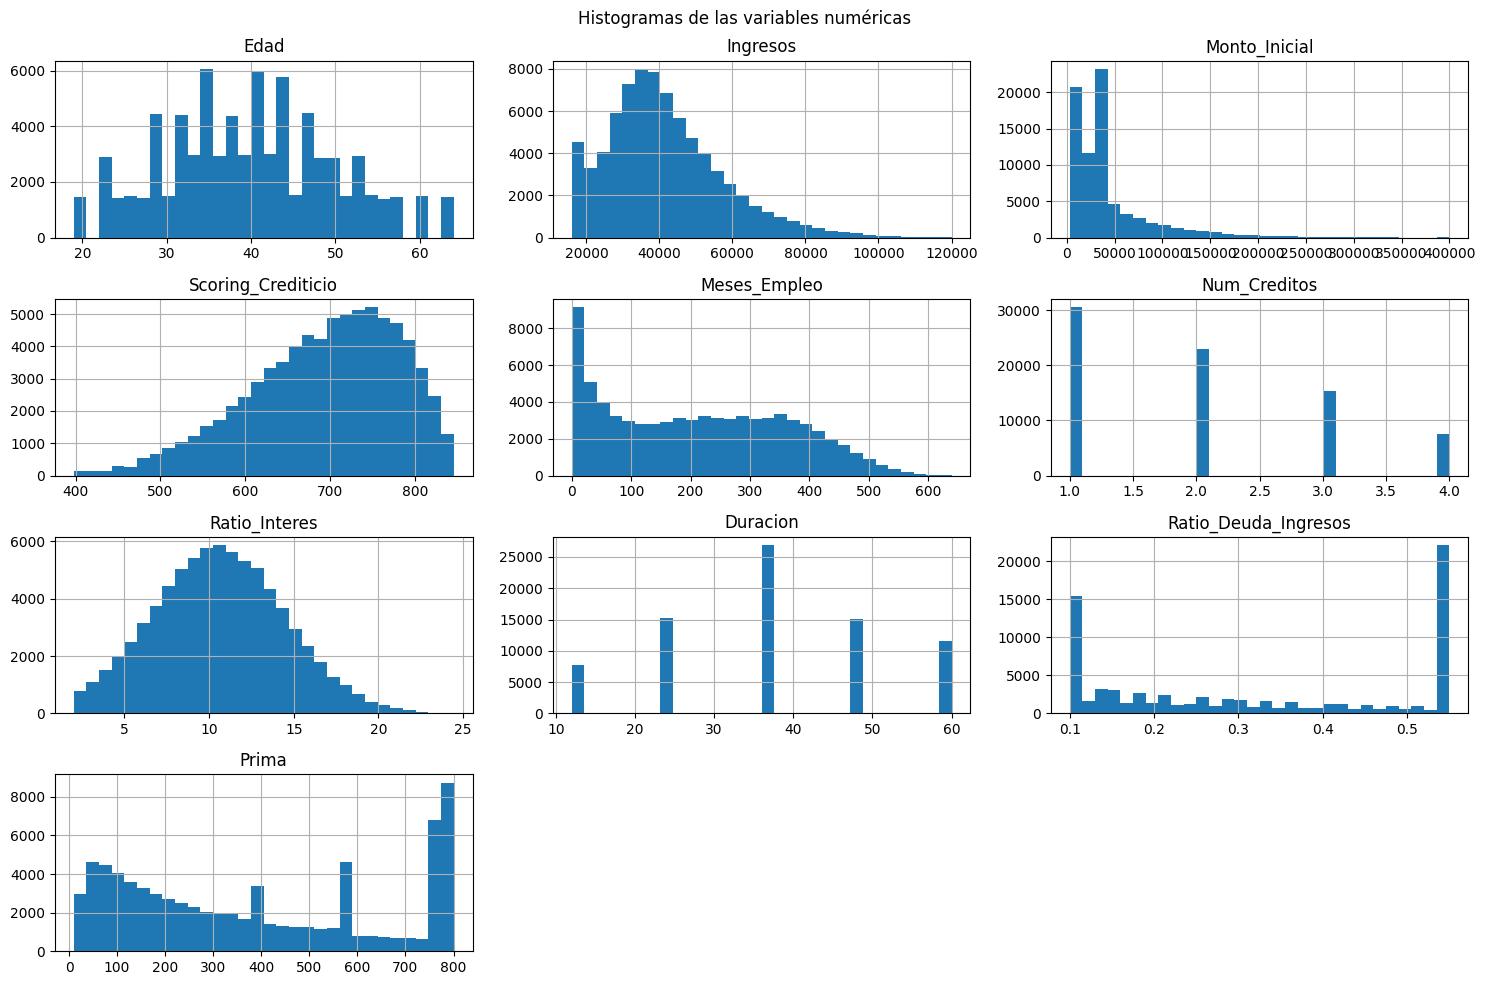

In [14]:
df[numericas].hist(bins=30, figsize=(15, 10))
plt.suptitle("Histogramas de las variables numéricas")
plt.tight_layout()
plt.show()

En los histogramas se ve que:

- *Edad* y *Scoring_Crediticio* tienen forma parecida a una campana (distribución más o menos normal).
- *Ingresos* y *Monto_Inicial* tienen asimetría a la derecha: la mayoría de valores son bajos y hay pocos valores muy altos.
- En *Monto_Inicial* se ve una barra muy alta en 40.000, y en *Ratio_Deuda_Ingresos* barras altas en los extremos, como vimos antes.
- En *Prima* hay una barra alta en 800 €.

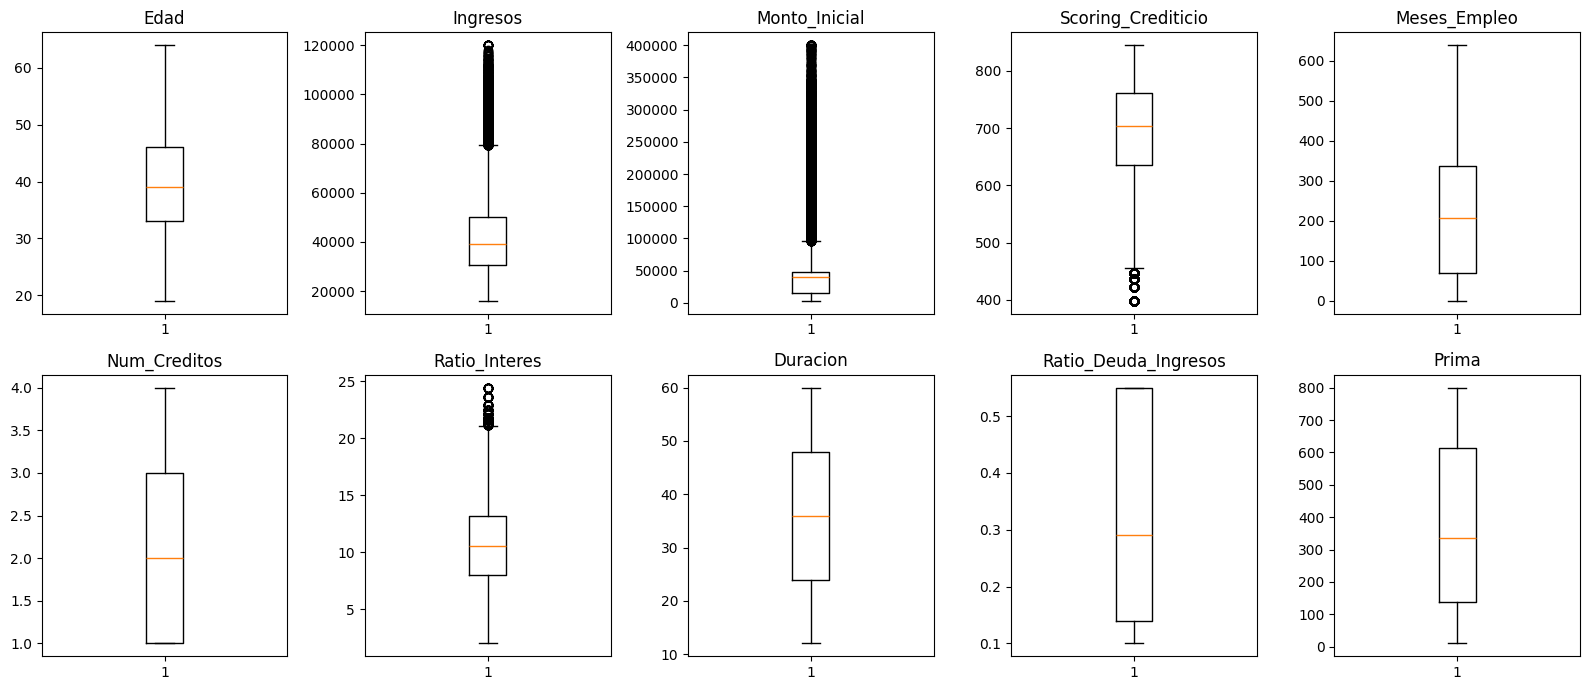

In [15]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for i, col in enumerate(numericas):
    ax = axes[i // 5, i % 5]
    ax.boxplot(df[col])
    ax.set_title(col)
plt.tight_layout()
plt.show()

En los diagramas de caja se ven valores atípicos (puntos por encima de la caja) sobre todo en *Ingresos* y *Monto_Inicial*. No los eliminamos porque son préstamos reales, simplemente más grandes que la media.

### 3.2 Variables categóricas

In [16]:
categoricas = ["Estudios", "Tipo_Jornada_Laboral", "Estado_Civil",
               "Posesion_Hipoteca", "Personas_Cargo", "Fiador"]

for col in categoricas:
    print(col)
    print((df[col].value_counts(normalize=True) * 100).round(2))
    print()

Estudios
Estudios
Escolar                38.87
Grado Universitario    37.27
Máster                 16.01
Doctorado               7.85
Name: proportion, dtype: float64

Tipo_Jornada_Laboral
Tipo_Jornada_Laboral
Jornada completa    55.27
Tiempo parcial      19.88
Autónomo            14.95
Desempleado          9.89
Name: proportion, dtype: float64

Estado_Civil
Estado_Civil
Casado        51.51
Soltero       30.10
Divorciado    18.39
Name: proportion, dtype: float64

Posesion_Hipoteca
Posesion_Hipoteca
0.0    65.02
1.0    34.98
Name: proportion, dtype: float64

Personas_Cargo
Personas_Cargo
0.0    55.06
1.0    44.94
Name: proportion, dtype: float64

Fiador
Fiador
0.0    70.03
1.0    29.97
Name: proportion, dtype: float64



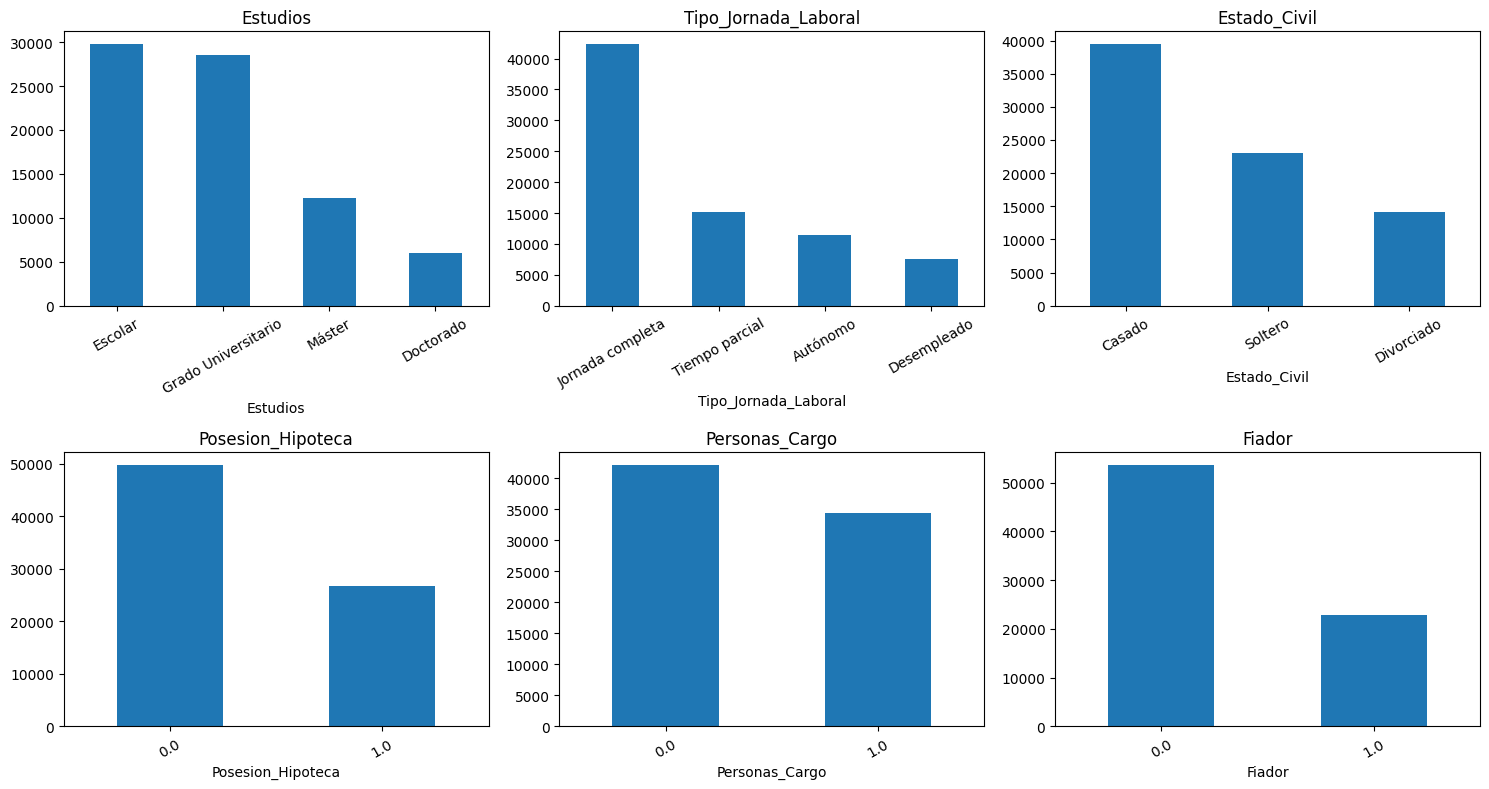

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(categoricas):
    ax = axes[i // 3, i % 3]
    df[col].value_counts().plot(kind="bar", ax=ax)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

- La mayoría tiene estudios escolares (39 %) o de grado (37 %).
- El 55 % trabaja a jornada completa y cerca del 10 % está desempleado.
- La mitad están casados.
- El 35 % tiene hipoteca, el 45 % tiene personas a su cargo y el 30 % tiene fiador.

## 4. Variable Impago

In [18]:
print(df["Impago"].value_counts())
print()
print((df["Impago"].value_counts(normalize=True) * 100).round(2))

Impago
0    67651
1     8859
Name: count, dtype: int64

Impago
0    88.42
1    11.58
Name: proportion, dtype: float64


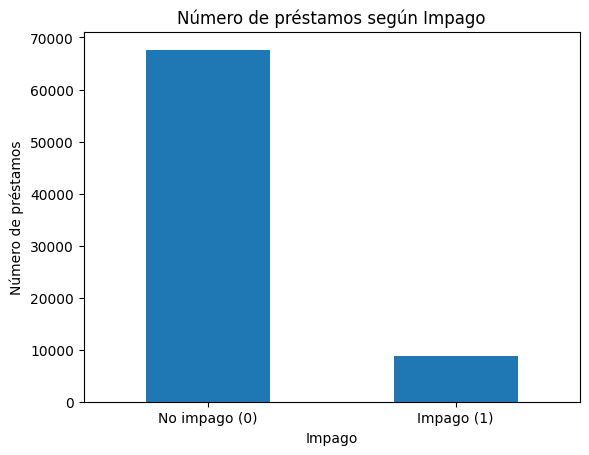

In [19]:
df["Impago"].value_counts().plot(kind="bar")
plt.title("Número de préstamos según Impago")
plt.xticks([0, 1], ["No impago (0)", "Impago (1)"], rotation=0)
plt.ylabel("Número de préstamos")
plt.show()

In [20]:
# Intervalo de confianza al 95 % para la proporción de impago
n = len(df)
p = df["Impago"].mean()
error = 1.96 * np.sqrt(p * (1 - p) / n)

print("Proporción de impago:", round(p * 100, 2), "%")
print("Intervalo de confianza 95 %: [", round((p - error) * 100, 2), "% ,", round((p + error) * 100, 2), "% ]")

Proporción de impago: 11.58 %
Intervalo de confianza 95 %: [ 11.35 % , 11.81 % ]


El **11,58 %** de los préstamos entra en impago. Con un 95 % de confianza, la proporción real de impago está entre el 11,35 % y el 11,81 %. El intervalo es muy estrecho porque tenemos muchos datos.

Las clases están **desbalanceadas**: hay unos 7,6 préstamos sin impago por cada uno con impago. Hay que tenerlo en cuenta en el modelo, porque un modelo que dijera siempre "no impago" acertaría el 88 % de las veces sin servir para nada.

## 5. Relación entre las variables y el Impago
### 5.1 Variables numéricas

In [21]:
df.groupby("Impago")[numericas].mean().round(2).T

Impago,0,1
Edad,40.220,35.300
Ingresos,"41,905.710","38,146.240"
Monto_Inicial,"45,899.770","39,154.540"
Scoring_Crediticio,693.510,685.140
Meses_Empleo,220.820,148.500
Num_Creditos,2.000,1.990
Ratio_Interes,10.480,12.060
Duracion,37.160,37.230
Ratio_Deuda_Ingresos,0.320,0.310
Prima,385.890,376.210


Comparando las medias de los que pagan (0) y los que no pagan (1):

- Los que impagan son **más jóvenes** (35 años frente a 40).
- Llevan **menos tiempo trabajando** (148 meses frente a 221).
- Tienen un **tipo de interés más alto** (12,1 % frente a 10,5 %).
- Tienen **menos ingresos** (38.146 € frente a 41.906 €).

En otras variables como la duración o el número de créditos las medias son casi iguales.

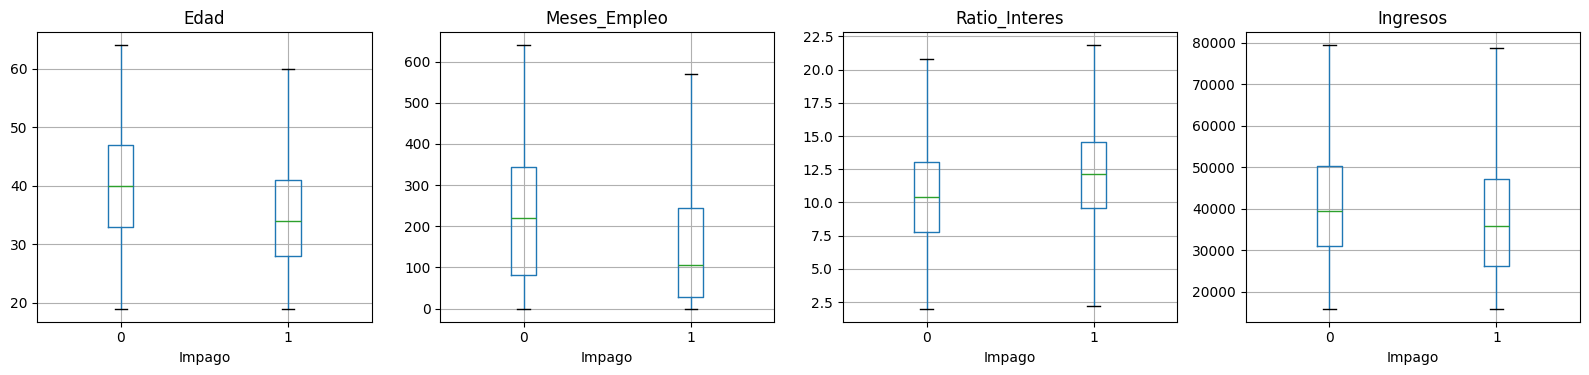

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
variables = ["Edad", "Meses_Empleo", "Ratio_Interes", "Ingresos"]
for i, col in enumerate(variables):
    df.boxplot(column=col, by="Impago", ax=axes[i], showfliers=False)
    axes[i].set_title(col)
    axes[i].set_xlabel("Impago")
plt.suptitle("")
plt.tight_layout()
plt.show()

Para comprobar si estas diferencias son **estadísticamente significativas** se usa la **prueba t de Student** para dos muestras independientes:

- **H0:** la media es igual en los que pagan y en los que no pagan.
- **H1:** las medias son distintas.

Se usa un nivel de significación de 0,05: si el p-valor es menor que 0,05, se rechaza H0.

In [23]:
pagan = df[df["Impago"] == 0]
no_pagan = df[df["Impago"] == 1]

for col in numericas:
    t, p_valor = stats.ttest_ind(pagan[col], no_pagan[col], equal_var=False)
    if p_valor < 0.05:
        conclusion = "Se rechaza H0 -> hay diferencia"
    else:
        conclusion = "No se rechaza H0 -> no hay diferencia"
    print(f"{col:22} p-valor = {p_valor:.4f}   {conclusion}")

Edad                   p-valor = 0.0000   Se rechaza H0 -> hay diferencia
Ingresos               p-valor = 0.0000   Se rechaza H0 -> hay diferencia
Monto_Inicial          p-valor = 0.0000   Se rechaza H0 -> hay diferencia
Scoring_Crediticio     p-valor = 0.0000   Se rechaza H0 -> hay diferencia
Meses_Empleo           p-valor = 0.0000   Se rechaza H0 -> hay diferencia
Num_Creditos           p-valor = 0.5019   No se rechaza H0 -> no hay diferencia
Ratio_Interes          p-valor = 0.0000   Se rechaza H0 -> hay diferencia
Duracion               p-valor = 0.6604   No se rechaza H0 -> no hay diferencia
Ratio_Deuda_Ingresos   p-valor = 0.0000   Se rechaza H0 -> hay diferencia
Prima                  p-valor = 0.0015   Se rechaza H0 -> hay diferencia


Hay diferencias significativas en casi todas las variables numéricas, salvo en **Num_Creditos** y **Duracion**, donde no se puede decir que las medias sean distintas.

Hay que tener en cuenta que con tantos datos (más de 76.000), incluso diferencias muy pequeñas salen significativas. Por eso además de mirar el p-valor hay que mirar **cuánto** cambia la media. Las diferencias más grandes están en la edad, los meses de empleo y el tipo de interés.

In [24]:
# Tasa de impago por grupos de edad
df["Grupo_Edad"] = pd.cut(df["Edad"], bins=[18, 30, 40, 50, 65],
                          labels=["19-30", "31-40", "41-50", "51-64"])
(df.groupby("Grupo_Edad", observed=True)["Impago"].mean() * 100).round(2)

,Impago
Grupo_Edad,
19-30,19.970
31-40,13.130
41-50,7.660
51-64,5.470


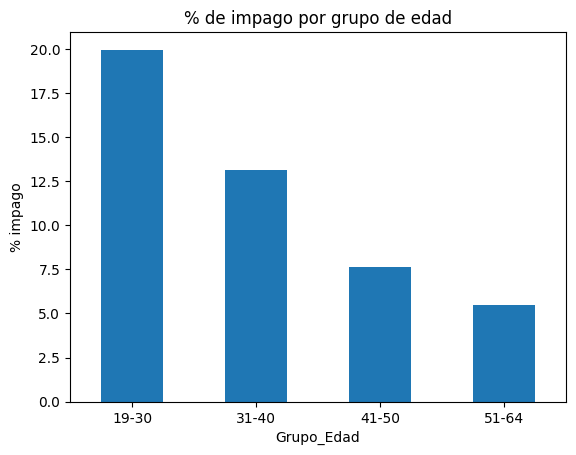

In [25]:
(df.groupby("Grupo_Edad", observed=True)["Impago"].mean() * 100).plot(kind="bar")
plt.title("% de impago por grupo de edad")
plt.ylabel("% impago")
plt.xticks(rotation=0)
plt.show()

Se ve claramente que **cuanto más joven, más riesgo de impago**. Los menores de 31 años impagan mucho más que los mayores de 50.

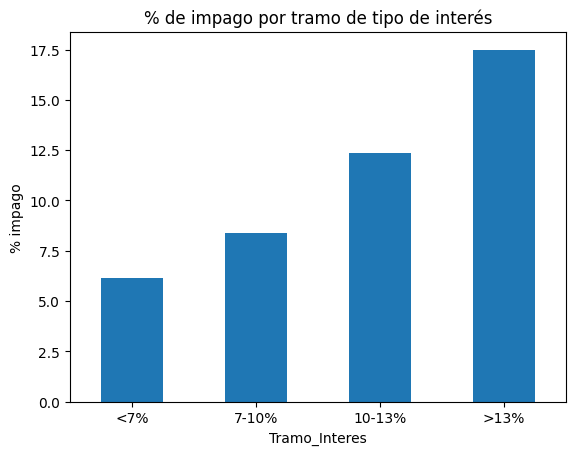

In [26]:
# Tasa de impago por tramos de tipo de interés
df["Tramo_Interes"] = pd.cut(df["Ratio_Interes"], bins=[0, 7, 10, 13, 25],
                             labels=["<7%", "7-10%", "10-13%", ">13%"])
(df.groupby("Tramo_Interes", observed=True)["Impago"].mean() * 100).plot(kind="bar")
plt.title("% de impago por tramo de tipo de interés")
plt.ylabel("% impago")
plt.xticks(rotation=0)
plt.show()

Lo mismo pasa con el tipo de interés: **a mayor tipo de interés, mayor impago**. Tiene lógica, porque a los clientes con más riesgo el banco les suele cobrar un interés más alto, y además la cuota es más cara.

### 5.2 Variables categóricas

In [27]:
for col in categoricas:
    print(col)
    print((pd.crosstab(df[col], df["Impago"], normalize="index") * 100).round(2))
    print()

Estudios
Impago                   0      1
Estudios                         
Doctorado            88.56  11.44
Escolar              89.94  10.06
Grado Universitario  87.20  12.80
Máster               87.52  12.48

Tipo_Jornada_Laboral
Impago                    0      1
Tipo_Jornada_Laboral              
Autónomo              88.14  11.86
Desempleado           88.49  11.51
Jornada completa      88.59  11.41
Tiempo parcial        88.14  11.86

Estado_Civil
Impago            0      1
Estado_Civil              
Casado        90.02   9.98
Divorciado    91.85   8.15
Soltero       83.58  16.42

Posesion_Hipoteca
Impago                 0      1
Posesion_Hipoteca              
0.0                88.38  11.62
1.0                88.50  11.50

Personas_Cargo
Impago              0      1
Personas_Cargo              
0.0             88.31  11.69
1.0             88.55  11.45

Fiador
Impago      0      1
Fiador              
0.0     88.41  11.59
1.0     88.45  11.55



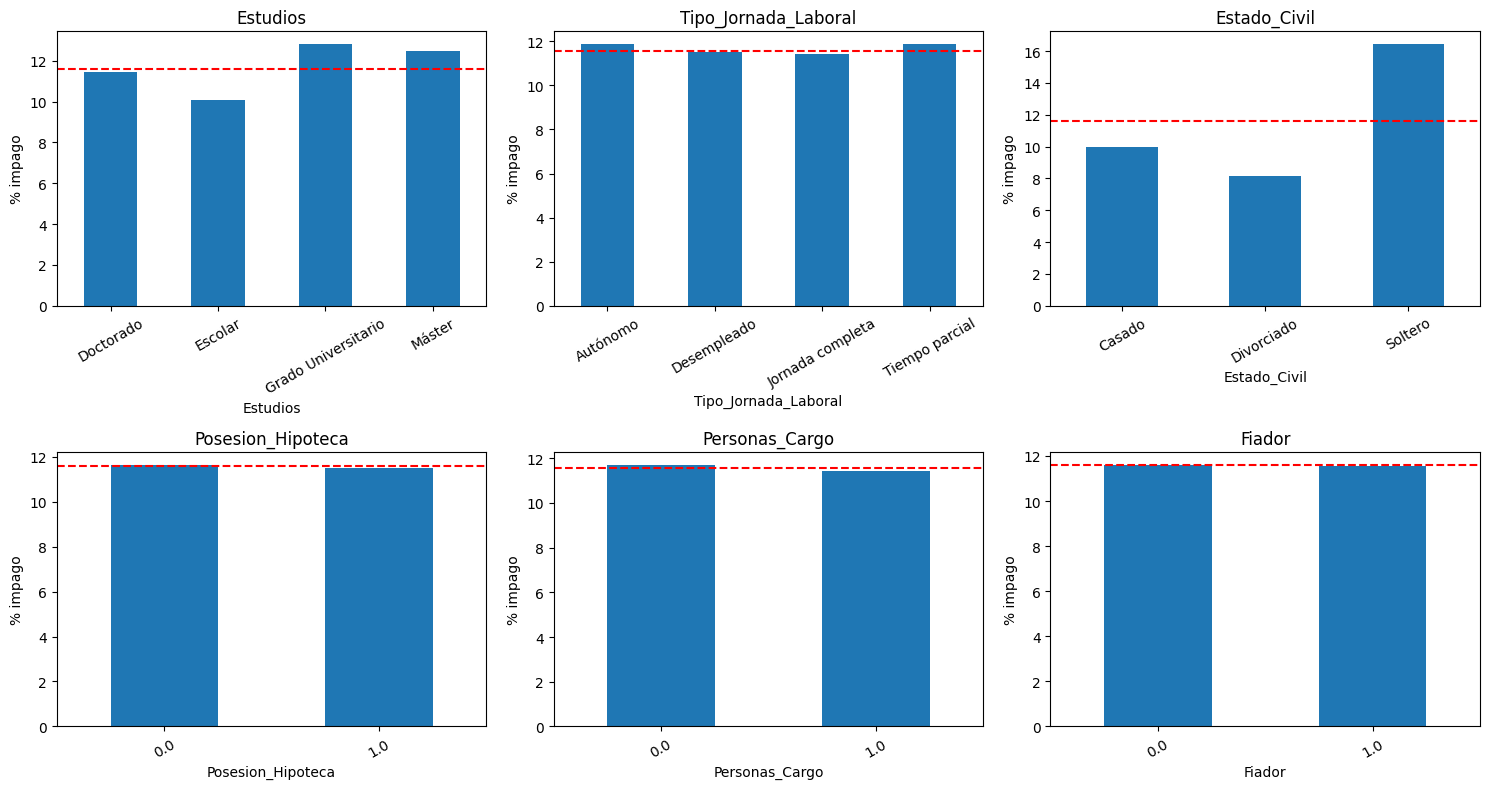

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(categoricas):
    ax = axes[i // 3, i % 3]
    (df.groupby(col)["Impago"].mean() * 100).plot(kind="bar", ax=ax)
    ax.axhline(df["Impago"].mean() * 100, color="red", linestyle="--")
    ax.set_title(col)
    ax.set_ylabel("% impago")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

Para comprobar si el impago depende de cada variable categórica usamos la **prueba chi-cuadrado de independencia**:

- **H0:** el impago es independiente de la variable.
- **H1:** el impago depende de la variable.

In [29]:
for col in categoricas:
    tabla = pd.crosstab(df[col], df["Impago"])
    chi2, p_valor, gl, esperados = stats.chi2_contingency(tabla)
    if p_valor < 0.05:
        conclusion = "Se rechaza H0 -> hay relación"
    else:
        conclusion = "No se rechaza H0 -> no hay relación"
    print(f"{col:22} p-valor = {p_valor:.4f}   {conclusion}")

Estudios               p-valor = 0.0000   Se rechaza H0 -> hay relación
Tipo_Jornada_Laboral   p-valor = 0.3624   No se rechaza H0 -> no hay relación
Estado_Civil           p-valor = 0.0000   Se rechaza H0 -> hay relación
Posesion_Hipoteca      p-valor = 0.6071   No se rechaza H0 -> no hay relación
Personas_Cargo         p-valor = 0.3053   No se rechaza H0 -> no hay relación
Fiador                 p-valor = 0.8652   No se rechaza H0 -> no hay relación


- **Estado_Civil** sí influye: los solteros impagan un 16,4 %, frente al 10 % de los casados y el 8,2 % de los divorciados.
- **Estudios** también, aunque la diferencia es pequeña.
- **Tipo_Jornada_Laboral, Posesion_Hipoteca, Personas_Cargo y Fiador no tienen relación** con el impago.

Esto último es sorprendente: sería lógico pensar que un desempleado impaga más que alguien con jornada completa, o que tener un fiador reduce el riesgo, pero en estos datos no pasa. Es algo que conviene comentar en el informe.

## 6. Análisis de la Prima

In [30]:
df["Prima"].describe().round(2)

,Prima
count,"76,510.000"
mean,384.770
std,267.320
min,10.000
25%,137.270
50%,335.950
75%,612.850
max,800.000


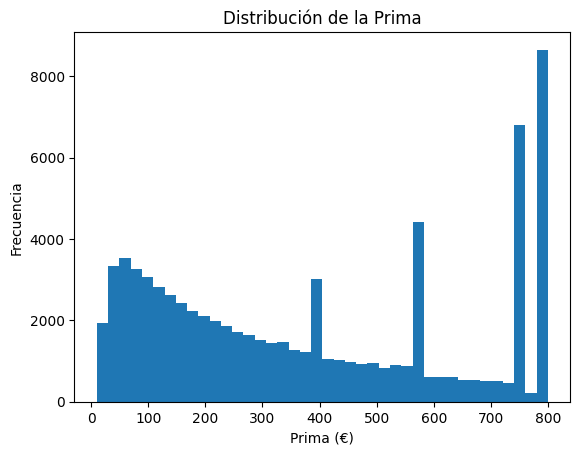

In [31]:
plt.hist(df["Prima"], bins=40)
plt.title("Distribución de la Prima")
plt.xlabel("Prima (€)")
plt.ylabel("Frecuencia")
plt.show()

In [32]:
# Correlación de cada variable numérica con la Prima
df[numericas].corr()["Prima"].sort_values(ascending=False).round(3)

,Prima
Prima,1.000
Ratio_Deuda_Ingresos,0.636
Monto_Inicial,0.628
Duracion,0.309
Ingresos,0.217
Ratio_Interes,0.137
Edad,0.113
Meses_Empleo,0.080
Num_Creditos,-0.002
Scoring_Crediticio,-0.071


Las variables que más se relacionan con la prima son **Ratio_Deuda_Ingresos** (0,64) y **Monto_Inicial** (0,63), seguidas de *Duracion* (0,31). Tiene sentido: cuanto más dinero se presta y durante más tiempo, más cuesta asegurarlo. *Ratio_Deuda_Ingresos* sale alta en parte porque está muy relacionada con el monto (lo vemos en el apartado 7).

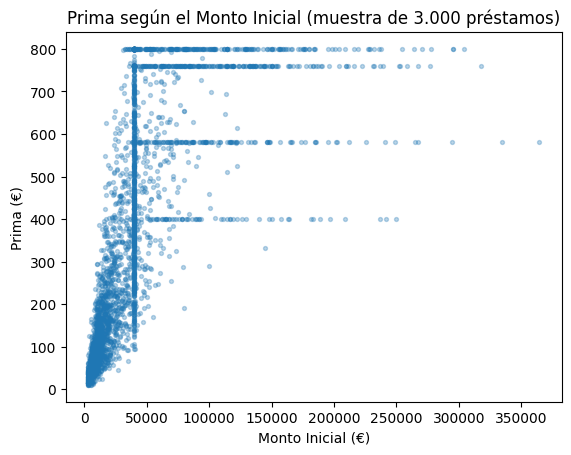

In [33]:
muestra = df.sample(3000, random_state=1)
plt.scatter(muestra["Monto_Inicial"], muestra["Prima"], alpha=0.3, s=8)
plt.title("Prima según el Monto Inicial (muestra de 3.000 préstamos)")
plt.xlabel("Monto Inicial (€)")
plt.ylabel("Prima (€)")
plt.show()

La prima sube rápidamente con el monto hasta unos 60.000 €, y a partir de ahí deja de subir. También se ven **líneas horizontales** en ciertos valores (400, 580, 760 y 800 €), lo que indica que la prima tiene un máximo.

In [34]:
df.groupby("Duracion")["Prima"].agg(["count", "mean", "max"]).round(2)

,count,mean,max
Duracion,,,
12.0,7785,211.810,400.000
24.0,15181,304.870,580.000
36.0,26914,394.870,760.000
48.0,15083,452.230,800.000
60.0,11547,494.780,800.000


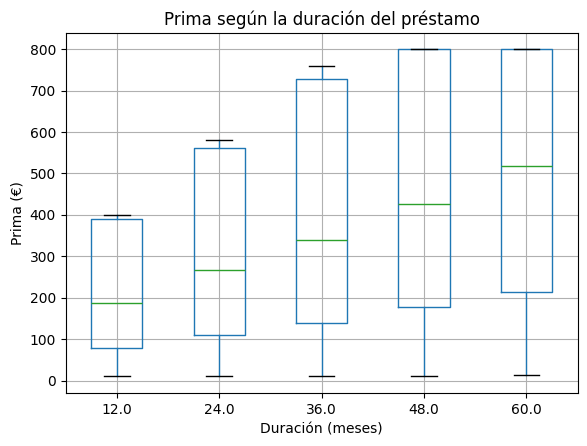

In [35]:
df.boxplot(column="Prima", by="Duracion")
plt.title("Prima según la duración del préstamo")
plt.suptitle("")
plt.xlabel("Duración (meses)")
plt.ylabel("Prima (€)")
plt.show()

Aquí se explica lo de las líneas horizontales: **la prima tiene un máximo distinto según la duración** del préstamo:

| Duración | Prima máxima |
|---|---|
| 12 meses | 400 € |
| 24 meses | 580 € |
| 36 meses | 760 € |
| 48 y 60 meses | 800 € |

Y la prima media sube con la duración.

In [36]:
# ¿Pagan más prima los que acaban en impago?
print(df.groupby("Impago")["Prima"].mean().round(2))

t, p_valor = stats.ttest_ind(pagan["Prima"], no_pagan["Prima"], equal_var=False)
print("p-valor:", round(p_valor, 4))

Impago
0    385.89
1    376.21
Name: Prima, dtype: float64
p-valor: 0.0015


Los clientes que acaban en impago pagan de media **376 €** de prima y los que no, **386 €**. La diferencia es estadísticamente significativa, pero es muy pequeña y además **va al revés de lo esperable**: los clientes con más riesgo pagan un poco menos.

Esto quiere decir que **la prima actual no tiene en cuenta el riesgo del cliente**, solo el tamaño y la duración del préstamo. Es una conclusión importante para Lagun Aro.

## 7. Correlaciones entre variables

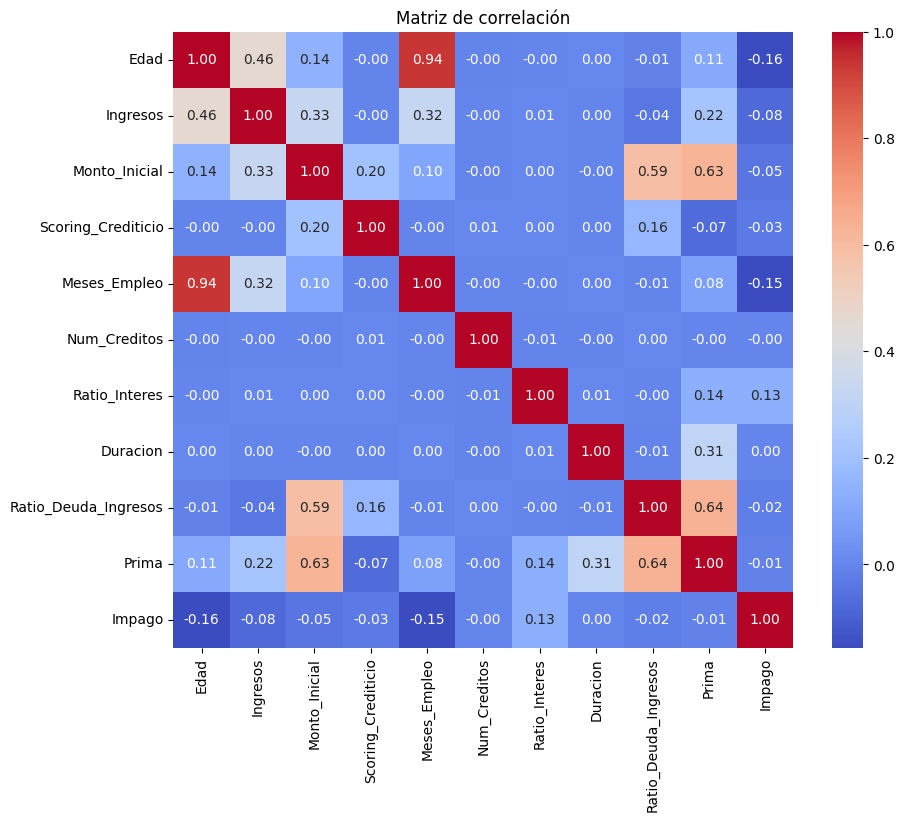

In [37]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[numericas + ["Impago"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matriz de correlación")
plt.show()

- **Edad y Meses_Empleo están muy correlacionadas (0,96)**. Tiene lógica: cuanto mayor es una persona, más tiempo ha podido trabajar. En el modelo no conviene meter las dos a la vez porque dan casi la misma información.
- *Monto_Inicial* también está bastante correlacionado con *Ratio_Deuda_Ingresos* y con *Prima*.
- Con el *Impago* ninguna variable tiene una correlación fuerte; las más altas son la edad y los meses de empleo (negativas) y el tipo de interés (positiva).

## 8. Conclusiones

**Sobre los datos**
- Se han eliminado 3 filas duplicadas y la variable *Proposito*, que era igual en todos los préstamos.
- Hay datos sospechosos: un 22 % de préstamos de exactamente 40.000 €, un 11 % de personas con más meses trabajados de lo posible y la variable *Ratio_Deuda_Ingresos* recortada en 0,10 y 0,55.

**Sobre el impago**
- El 11,6 % de los préstamos entra en impago. Las clases están desbalanceadas.
- Tienen más riesgo las personas **jóvenes**, con **poca experiencia laboral**, **menos ingresos**, **tipo de interés alto** y **solteras**.
- El tipo de jornada, tener hipoteca, tener personas a cargo o tener fiador **no influyen** en el impago.

**Sobre la prima**
- Depende sobre todo del **monto** y de la **duración** del préstamo, y tiene un máximo según la duración.
- **No depende del riesgo de impago**, así que un modelo de impago podría ayudar a Lagun Aro a ajustar mejor el precio del seguro.

**Para los modelos**
- No usar a la vez *Edad* y *Meses_Empleo*.
- Tener en cuenta el desbalance del impago al evaluar el modelo.